# Musterlösung 0 · Kompatibilität und Integration
Wir verfolgen eine Messung von der CSV-Datei bis zur Prognose. An der Kalibrierung um 11:00 Uhr lässt sich prüfen, ob der Zeit-Join den damaligen Wissensstand abbildet. Der [Walkthrough](WALKTHROUGH.md) enthält Kontrollwerte und Fragen für die Besprechung.

## A · Was bedeutet eine Zeile?
Die Startzelle lädt die vier CSV-Dateien. Prüft Datentypen, Ebenen und Zeitbereiche. Welche Schlüssel identifizieren eine Messung, eine Maschine, einen Wartungsbeginn und einen Referenzwert? Wie häufig misst M1? Welche Einheiten und Zeitzonen gehen aus den Dateien hervor?

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Funktioniert im Aufgabenordner und bei einem Start aus der Repository-Wurzel.
for basis in (Path.cwd(), *Path.cwd().parents):
    for ordner in (basis, basis / "tasks" / "00_compatibility_and_integration"):
        daten = ordner / "data"
        if (daten / "zeitreihe_roh.csv").is_file():
            break
    else:
        continue
    break
else:
    raise FileNotFoundError("Aufgabenordner mit den vier CSV-Dateien nicht gefunden.")

messung = pd.read_csv(daten / "zeitreihe_roh.csv", parse_dates=["timestamp"])
stamm = pd.read_csv(daten / "maschinenstamm.csv", parse_dates=["commissioned"])
wartung = pd.read_csv(daten / "wartung.csv", parse_dates=["maintenance_start"])
ziel = pd.read_csv(daten / "prognose_zielreihe.csv", parse_dates=["timestamp"])

schluessel = ["machine_id", "timestamp"]
signale = ["temp_raw", "vibration_raw"]
messung = messung.sort_values(schluessel).reset_index(drop=True)
for name, tabelle in {"Messungen": messung, "Stamm": stamm, "Wartung": wartung, "Referenz": ziel}.items():
    print(f"{name} ({len(tabelle)} Zeilen)")
    display(tabelle.head(2))

Messungen (40 Zeilen)


,timestamp,machine_id,temp_raw,vibration_raw
0,2025-01-01 08:00:00,M1,20.25,53.30
1,2025-01-01 08:15:00,M1,20.32,53.05


Stamm (2 Zeilen)


,machine_id,location,commissioned,criticality
0,M1,Halle_A,2023-06-10,hoch
1,M2,Halle_B,2024-03-21,mittel


Wartung (3 Zeilen)


,machine_id,maintenance_start,maintenance_type,technician
0,M1,2024-12-15 09:00:00,Inspektion,Meier
1,M1,2025-01-01 11:00:00,Kalibrierung,Keller


Referenz (20 Zeilen)


,timestamp,machine_id,temp_clean_target
0,2025-01-01 08:00:00,M1,19.93
1,2025-01-01 08:15:00,M1,20.32


In [2]:
for tabelle, key in [(messung, schluessel), (stamm, ["machine_id"]),
                     (wartung, ["machine_id", "maintenance_start"]), (ziel, schluessel)]:
    assert tabelle[key].notna().all().all()
    assert not tabelle.duplicated(key).any()
for tabelle in [messung, ziel]:
    display(tabelle.groupby("machine_id")["timestamp"].agg(["min", "max", "count"]))
abstaende = messung.groupby("machine_id")["timestamp"].diff().dropna()
display(abstaende.value_counts().rename("Anzahl Abstände").to_frame())
assert abstaende.eq(pd.Timedelta(minutes=15)).all()
display(messung[signale].isna().sum().rename("Fehlende Werte").to_frame())

,min,max,count
machine_id,,,
M1,2025-01-01 08:00:00,2025-01-01 17:45:00,40


,min,max,count
machine_id,,,
M1,2025-01-01 08:00:00,2025-01-01 12:45:00,20


,Anzahl Abstände
timestamp,
0 days 00:15:00,39


,Fehlende Werte
temp_raw,7
vibration_raw,3


Die Dateien verwenden dieselben Maschinenkennungen. M2 existiert im Stamm und im Wartungslog, liefert hier aber keine Sensormessungen. Die Zeitstempel haben keine Zeitzone. Wir nehmen für diese Übung eine gemeinsame Uhrzeit und Temperaturskala (°C gemäss Vorlage) an. Für die Vibration ist keine Einheit dokumentiert. Messwert, Wartungsbeginn und Referenztemperatur haben jeweils eine andere Bedeutung.

## B · Was war um 08:45 Uhr bekannt?
Vergleicht für **beide Signale** Forward Fill, Backward Fill und zeitbasierte lineare Interpolation. Beginnt mit jeder Methode bei denselben Rohwerten und rechnet je Maschine. Behaltet die Rohwerte sowie ein Kennzeichen für ersetzte Werte. Zeigt die Temperatur von 08:30 bis 09:15 Uhr. Welche Schätzung wäre um 08:45 Uhr im laufenden Betrieb möglich gewesen?

In [3]:
gruppen = []
for _, gruppe in messung.groupby("machine_id"):
    gruppe = gruppe.set_index("timestamp").sort_index()
    for signal in signale:
        roh = gruppe[signal]
        gruppe[f"{signal}_fehlte"] = roh.isna()
        gruppe[f"{signal}_ffill"] = roh.ffill()
        gruppe[f"{signal}_bfill"] = roh.bfill()
        gruppe[f"{signal}_interp"] = roh.interpolate(method="time", limit_area="inside")
    gruppen.append(gruppe.reset_index())
vergleich = pd.concat(gruppen, ignore_index=True)
ausschnitt = vergleich.query("machine_id == 'M1'").set_index("timestamp").between_time("08:30", "09:15")
display(ausschnitt.filter(regex="^temp_raw").round(3))

,temp_raw,temp_raw_fehlte,temp_raw_ffill,temp_raw_bfill,temp_raw_interp
timestamp,,,,,
2025-01-01 08:30:00,21.09,False,21.09,21.09,21.090
2025-01-01 08:45:00,NaN,True,21.09,21.76,21.313
2025-01-01 09:00:00,NaN,True,21.09,21.76,21.537
2025-01-01 09:15:00,21.76,False,21.76,21.76,21.760


Rückblickend ergibt Interpolation um 08:45 Uhr rund 21.31 °C. Im laufenden Betrieb lag als letzter Messwert nur 21.09 °C vor. Der nächste gültige Wert von 21.76 °C traf erst um 09:15 Uhr ein. Beide Schätzungen bleiben im Protokoll als imputiert erkennbar.

## C · Welche Wartung gehört zur Messung?
Verknüpft zuerst die Messungen mit dem Maschinenstamm. Garantiert, dass jede Messung genau einmal erhalten bleibt. Ordnet danach jeder Messung den **letzten Wartungsbeginn derselben Maschine bis und mit Messzeitpunkt** zu. Prüft M1 um 10:45 und um 11:00 Uhr. Was würde ein Join allein auf `machine_id` mit der Zeilenzahl machen?

In [4]:
mit_stamm = vergleich.merge(stamm, on="machine_id", how="left", validate="many_to_one", indicator=True)
assert mit_stamm["_merge"].eq("both").all()
mit_stamm = mit_stamm.drop(columns="_merge")

nur_id = mit_stamm.merge(wartung, on="machine_id", how="left")
print(f"Join auf Maschinen-ID allein: {len(nur_id)} Zeilen für {len(mit_stamm)} Messungen")

integriert = pd.merge_asof(
    mit_stamm.sort_values("timestamp"), wartung.sort_values("maintenance_start"),
    by="machine_id", left_on="timestamp", right_on="maintenance_start",
    direction="backward", allow_exact_matches=True,
)
assert len(integriert) == len(messung) and not integriert.duplicated(schluessel).any()
treffer = integriert.dropna(subset=["maintenance_start"])
assert (treffer["maintenance_start"] <= treffer["timestamp"]).all()
kontrolle = integriert.query("machine_id == 'M1'").set_index("timestamp").between_time("10:45", "11:00")
display(kontrolle[["location", "criticality", "maintenance_type", "maintenance_start"]])
assert kontrolle["maintenance_type"].tolist() == ["Inspektion", "Kalibrierung"]

Join auf Maschinen-ID allein: 80 Zeilen für 40 Messungen


,location,criticality,maintenance_type,maintenance_start
timestamp,,,,
2025-01-01 10:45:00,Halle_A,hoch,Inspektion,2024-12-15 09:00:00
2025-01-01 11:00:00,Halle_A,hoch,Kalibrierung,2025-01-01 11:00:00


Um 10:45 Uhr war zuletzt die Inspektion im Dezember gestartet, um 11:00 Uhr die Kalibrierung. Eine Endzeit fehlt. Wir können einer Messung die zuletzt begonnene Wartung zuordnen. Ob die Maschine dabei noch in Wartung war, bleibt offen.

## D · Rückblick und Vorhersage
**Rückblick.** Verwendet die interpolierte Temperatur von M1 aus der integrierten Tabelle. Glättet die Reihe mit einem nachlaufenden Mittel über drei Messungen (`min_periods=1`). Verknüpft die Schätzung mit `temp_clean_target` anhand von Maschine und Zeitpunkt. Berechnet den mittleren absoluten Fehler (MAE) und zeichnet Schätzung und Referenz im gemeinsamen Zeitfenster.

20 Zeitpunkte, MAE der Approximation: 1.068 °C


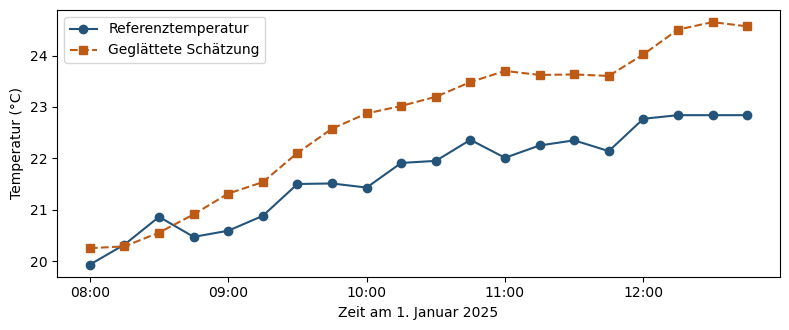

In [5]:
m1 = integriert.query("machine_id == 'M1'").set_index("timestamp").sort_index().copy()
m1["schaetzung"] = m1["temp_raw_interp"].rolling(3, min_periods=1).mean()
paare = m1.reset_index().merge(ziel, on=schluessel, how="inner", validate="one_to_one")
mae = (paare["schaetzung"] - paare["temp_clean_target"]).abs().mean()
print(f"{len(paare)} Zeitpunkte, MAE der Approximation: {mae:.3f} °C")
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(paare["timestamp"], paare["temp_clean_target"], "o-", color="#24547a", label="Referenztemperatur")
ax.plot(paare["timestamp"], paare["schaetzung"], "s--", color="#bd5b16", label="Geglättete Schätzung")
ax.legend()
ax.set(xlabel="Zeit am 1. Januar 2025", ylabel="Temperatur (°C)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
plt.tight_layout()
plt.show()

**Vorhersage.** Die Hilfsfunktion berechnet zwei Prognosen für vier Viertelstunden. Die erste schreibt die letzte Temperatur fort, die zweite verlängert den linearen Trend der letzten vier Viertelstunden. Übergebt die ausschliesslich vorwärts gefüllte Temperatur von M1 mit Zeitindex. Testet die Funktion zuerst mit Daten bis **11:45 Uhr** und vergleicht beide Prognosen mit den vier späteren Referenzwerten. Erstellt dann mit Daten bis **17:45 Uhr** die Vorschau für 18:00 bis 18:45 Uhr. Für welche dieser Aussagen könnt ihr einen Prognosefehler berechnen?

In [6]:
def prognose(historie):
    # Eingabe: lückenloses 15-Minuten-Raster einer Maschine, nur bis zum Prognoseursprung.
    fenster = historie.sort_index().tail(4)
    schritt = pd.Timedelta(minutes=15)
    if len(fenster) != 4 or fenster.isna().any() or not fenster.index.to_series().diff().iloc[1:].eq(schritt).all():
        raise ValueError("Vier aufeinanderfolgende, verfügbare Viertelstunden erforderlich.")
    steigung, achsenabschnitt = np.polyfit(np.arange(4), fenster.to_numpy(), 1)
    zeiten = pd.date_range(fenster.index[-1] + schritt, periods=4, freq=schritt, name="timestamp")
    return pd.DataFrame({
        "Letzter Wert": fenster.iloc[-1],
        "Linearer Trend": achsenabschnitt + steigung * np.arange(4, 8),
    }, index=zeiten)

In [7]:
live = m1["temp_raw_ffill"]
test = prognose(live.loc[:"2025-01-01 11:45"])
referenz = ziel.query("machine_id == 'M1'").set_index("timestamp")["temp_clean_target"]
ist = referenz.reindex(test.index)
assert ist.notna().all()
display(test.join(ist).round(3))
display(test.sub(ist, axis="index").abs().mean().rename("MAE (°C)").round(4).to_frame())

zukunft = prognose(live)
display(zukunft.round(3))

,Letzter Wert,Linearer Trend,temp_clean_target
timestamp,,,
2025-01-01 12:00:00,23.54,23.255,22.77
2025-01-01 12:15:00,23.54,23.113,22.84
2025-01-01 12:30:00,23.54,22.971,22.84
2025-01-01 12:45:00,23.54,22.829,22.84


,MAE (°C)
Letzter Wert,0.7175
Linearer Trend,0.2250


,Letzter Wert,Linearer Trend
timestamp,,
2025-01-01 18:00:00,20.8,20.050
2025-01-01 18:15:00,20.8,19.708
2025-01-01 18:30:00,20.8,19.366
2025-01-01 18:45:00,20.8,19.024


### Einordnung für die Schichtleitung
Im vier Punkte langen Testfenster hat der lokale Trend den kleineren MAE. Am Schichtende liefert er für 18:45 Uhr rund 19.02 °C, das Fortschreiben des letzten Werts 20.80 °C. Der Trend hängt stark von den letzten vier Messungen ab. Ohne Referenzwerte nach 17:45 Uhr bleibt die Genauigkeit beider Vorschauen offen.

**KI-Check für die Besprechung.** Falls ein Vorschlag die zeitlich nächste Wartung auswählt, prüft 10:45 Uhr. Die Kalibrierung läge zeitlich nahe, ihr Beginn um 11:00 Uhr liegt aber nach der Messung. Die Daten enthalten nur den tatsächlichen Beginn. Die fachliche Regel verlangt den letzten bereits erreichten Beginn.